# 2 — Playing styles: eight kinds of player

**In brief**
- **Question:** What kinds of players are there, judged by *how* they play rather than how well?
- **Answer:** Style is mostly a continuum, but it slices into eight recognisable kinds, found by the data and named afterwards: Mr. Inside the Key, Windex, Bruiser, The Pest, Give Me the Ball and Let Me Work, Peter Griffin's NBA Jam, Kerr's Cult and The Effective Operator. Players move between kinds as their game changes. Over 2000-26 the traditional rim big fell from about a quarter of players to 5%, while the corner 3-and-D wing rose to a fifth.
- **Decisions** ([decision log](../docs/DECISIONS.md)): [D31](../docs/DECISIONS.md) (no expected types written down first), [D34](../docs/DECISIONS.md) (the set-up), [D35](../docs/DECISIONS.md) (eight clusters), [D36](../docs/DECISIONS.md) (2000-26 with no era adjustment), [D37](../docs/DECISIONS.md) (the names). Write-up: [the eight kinds of player](../docs/EIGHT_CLUSTERS.md).
- **Where it fits:** Stands on its own. It will feed the comparisons of similar players (Phase C) and the question of whether changing your game pays off (Phase E).
- **Dated:** written 13 November 2026 from notebook 13 (now in [archive/](archive/13_archetypes.ipynb)), which has every intermediate step, including the five-cluster view.

**How it was done, in short** ([D34](../docs/DECISIONS.md)):
- **Style, not quality.** 15 measures of where a player shoots, how he creates, how he rebounds and his box-score defence. Shooting percentages, plus-minus and all-in-one ratings are left out on purpose, so a good and a bad rim-runner land in the same group.
- **Each measure is compared within its own season,** because the league changed (the share of shots from three nearly doubled; [notebook 0](0_data.ipynb)).
- **Every player-season with 500+ minutes, 2011-12 → 2025-26.** Body measures are left out and shown only afterwards, to see which kinds are size-bound.
- **Soft membership:** a Gaussian mixture gives each season a share in every group.
- **The data drew the groups; we named them afterwards.** No list of expected types and no names were written first ([D31](../docs/DECISIONS.md)), so the analysis cannot force players into categories we already believe in.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import archetypes as A
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, ORANGE, SERIES8, apply_style
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
pd.set_option("display.max_colwidth", None)
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
P = ps[ps["min"] >= 500].copy()
X = (P.groupby("season_start")[A.FEATURES].transform(lambda s: (s - s.mean()) / s.std())   # each measure within its season
     .fillna(0).to_numpy())                                                                  # no corner threes taken = that season's average
pc = A.style_axes(X)                     # the two main directions: inside → perimeter, off-ball → on-ball
print(f"{len(P):,} player-seasons with 500+ minutes, 2011-12 → 2025-26 ({P.groupby('season').size().min()}–{P.groupby('season').size().max()} a season); "
      f"{len(A.FEATURES)} style measures")
pd.DataFrame([(g, A.SHORT[c]) for g, cs in A.GROUPS.items() for c in cs], columns=["group", "measure"]).groupby("group", sort=False)["measure"].apply(", ".join).to_frame()

5,353 player-seasons with 500+ minutes, 2011-12 → 2025-26 (331–378 a season); 15 style measures


,measure
group,
where he shoots,"rim shots, paint (not rim), mid-range, threes, corner threes, free throws"
how he creates,"usage, self-created makes, assists, fast breaks"
rebounding,"offensive boards, defensive boards"
defence (box score),"blocks, steals, fouls"


## 2A — How many kinds are there?

Three ways to judge a number of groups:
1. **Stability:** fit on one random half of the seasons, then on the other half, and measure how often the two fits put the same seasons together (adjusted Rand index: 1 = identical, 0 = chance). Real groups come back every time; arbitrary slices of a continuum do not. Each number is the average over 20 pairs of halves; a single pair can differ from it by 0.1 or more.
2. **Separation:** how much closer each season is to its own group than to the next one (silhouette: 1 = far apart, 0 = touching).
3. **Fit** (BIC, lower is better). With 5,000+ seasons it keeps rewarding more groups, so it is the weakest guide.

,stability (soft mixture),stability (k-means),separation
clusters,,,
2,0.94,0.96,0.25
3,0.94,0.96,0.19
4,0.78,0.69,0.13
5,0.83,0.88,0.11
6,0.79,0.80,0.10
7,0.59,0.63,0.10
8,0.54,0.59,0.07
10,0.50,0.63,0.07
14,0.52,0.54,0.07


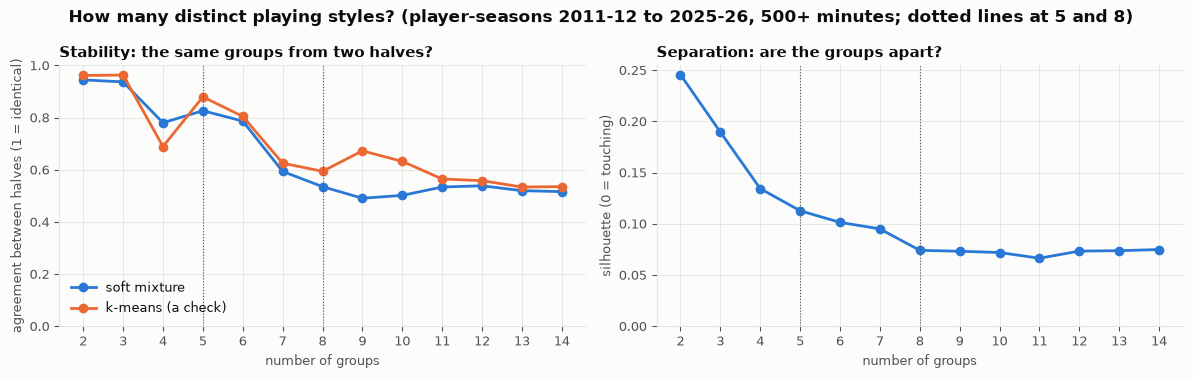

In [2]:
how_many = A.how_many(X, range(2, 15), repeats=20)      # 20 pairs of halves: 6 (as in notebook 13) left the estimate noisy
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(how_many.index, how_many["stability (soft mixture)"], color=BLUE, marker="o", label="soft mixture")
axes[0].plot(how_many.index, how_many["stability (k-means)"], color=ORANGE, marker="o", label="k-means (a check)")
axes[0].set_ylim(0, 1); axes[0].set_ylabel("agreement between halves (1 = identical)"); axes[0].legend(frameon=False, loc="lower left")
axes[0].set_title("Stability: the same groups from two halves?", loc="left", fontsize=11)
axes[1].plot(how_many.index, how_many["separation"], color=BLUE, marker="o"); axes[1].set_ylim(0, None)
axes[1].set_ylabel("silhouette (0 = touching)"); axes[1].set_title("Separation: are the groups apart?", loc="left", fontsize=11)
for ax in axes:
    ax.set_xticks(how_many.index); ax.set_xlabel("number of groups")
    for k in (5, 8):
        ax.axvline(k, color=INK2, linewidth=0.8, linestyle=":")
fig.suptitle("How many distinct playing styles? (player-seasons 2011-12 to 2025-26, 500+ minutes; dotted lines at 5 and 8)", x=0.06, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_how_many_kinds.png", dpi=150, bbox_inches="tight")
how_many.loc[[2, 3, 4, 5, 6, 7, 8, 10, 14], ["stability (soft mixture)", "stability (k-means)", "separation"]].round(2)

## 2B — The eight kinds

Eight were chosen ([D35](../docs/DECISIONS.md)), knowing they are less stable than five, because the eight fit neatly inside the five and each extra split has a clear basketball reading. Groups are numbered from the most inside (1) to the most perimeter (8). For each: its **best-known** members (most minutes among seasons 90%+ in the group) and its **most typical** ones (closest to the centre; these tend to be role players, because stars are extreme even within their type). The names came last ([D37](../docs/DECISIONS.md)).

In [3]:
NAMES = {1: "Mr. Inside the Key", 2: "Windex", 3: "Bruiser", 4: "The Pest", 5: "Give Me the Ball and Let Me Work",
         6: "Peter Griffin's NBA Jam", 7: "Kerr's Cult", 8: "The Effective Operator"}
rows = P[["player_id", "player_name", "season", "season_start", "min", "height_in", "weight_lb", "position_listed"]]
lab8, memb8, typical8, known8 = A.fit_clusters(X, 8, pc, rows)
lab5, _, _, _ = A.fit_clusters(X, 5, pc, rows)
P["kind"], P["kind_name"], P["membership"] = lab8, pd.Series(lab8, index=P.index).map(NAMES), memb8
prof = pd.DataFrame(X, columns=A.FEATURES, index=P.index).groupby(P["kind"]).mean()
sizes = P.groupby("kind").agg(height=("height_in", "median"), weight=("weight_lb", "median"))
nest = pd.crosstab(lab8, lab5, normalize="index")
summary = pd.DataFrame({"name": pd.Series(NAMES), "share of player-seasons": P["kind"].value_counts(normalize=True).sort_index(),
                        "best-known": [", ".join(known8[c]["player_name"].head(4)) for c in range(1, 9)],
                        "does more / less": [A.traits(prof.loc[c]).replace("\n", " / ").replace("more: ", "").replace("less: ", "") for c in range(1, 9)],
                        "typical height": [f"{h // 12:.0f}'{h % 12:.0f}\"" for h in sizes["height"]],
                        "inside group (of five)": nest.idxmax(axis=1).to_numpy(), "of which": nest.max(axis=1).to_numpy()})
print(f"seasons 70%+ in one group: {(memb8 >= 0.7).mean():.0%}")
summary.style.format({"share of player-seasons": "{:.0%}", "of which": "{:.0%}"})

seasons 70%+ in one group: 89%


,name,share of player-seasons,best-known,does more / less,typical height,inside group (of five),of which
1,Mr. Inside the Key,12%,"DeAndre Jordan, Rudy Gobert, Dwight Howard, Steven Adams","rim shots, offensive boards, blocks / threes, mid-range","6'11""",1,100%
2,Windex,12%,"Karl-Anthony Towns, Amen Thompson, Domantas Sabonis, David Lee","defensive boards, paint (not rim), / offensive boards / threes, fast breaks","6'10""",2,94%
3,Bruiser,8%,"Al Horford, Michael Porter Jr., Brook Lopez, Myles Turner","defensive boards, blocks, fouls / self-created makes, fast breaks","6'10""",2,59%
4,The Pest,16%,"Mikal Bridges, Thaddeus Young, Josh Hart, OG Anunoby","fast breaks, corner threes, steals / usage, assists","6'7""",3,87%
5,Give Me the Ball and Let Me Work,14%,"James Harden, Kevin Durant, Andrew Wiggins, Bradley Beal","self-created makes, assists, usage / fouls, offensive boards","6'5""",4,93%
6,Peter Griffin's NBA Jam,9%,"Trevor Ariza, P.J. Tucker, Toumani Camara, Dorian Finney-Smith","threes, corner threes / self-created makes, paint (not rim)","6'7""",3,52%
7,Kerr's Cult,15%,"Mikal Bridges, Nicolas Batum, Klay Thompson, Marcus Morris Sr.","threes / rim shots, offensive boards","6'5""",5,78%
8,The Effective Operator,15%,"Damian Lillard, Monta Ellis, Stephen Curry, Bradley Beal","self-created makes, assists, usage / defensive boards, offensive boards","6'3""",4,95%


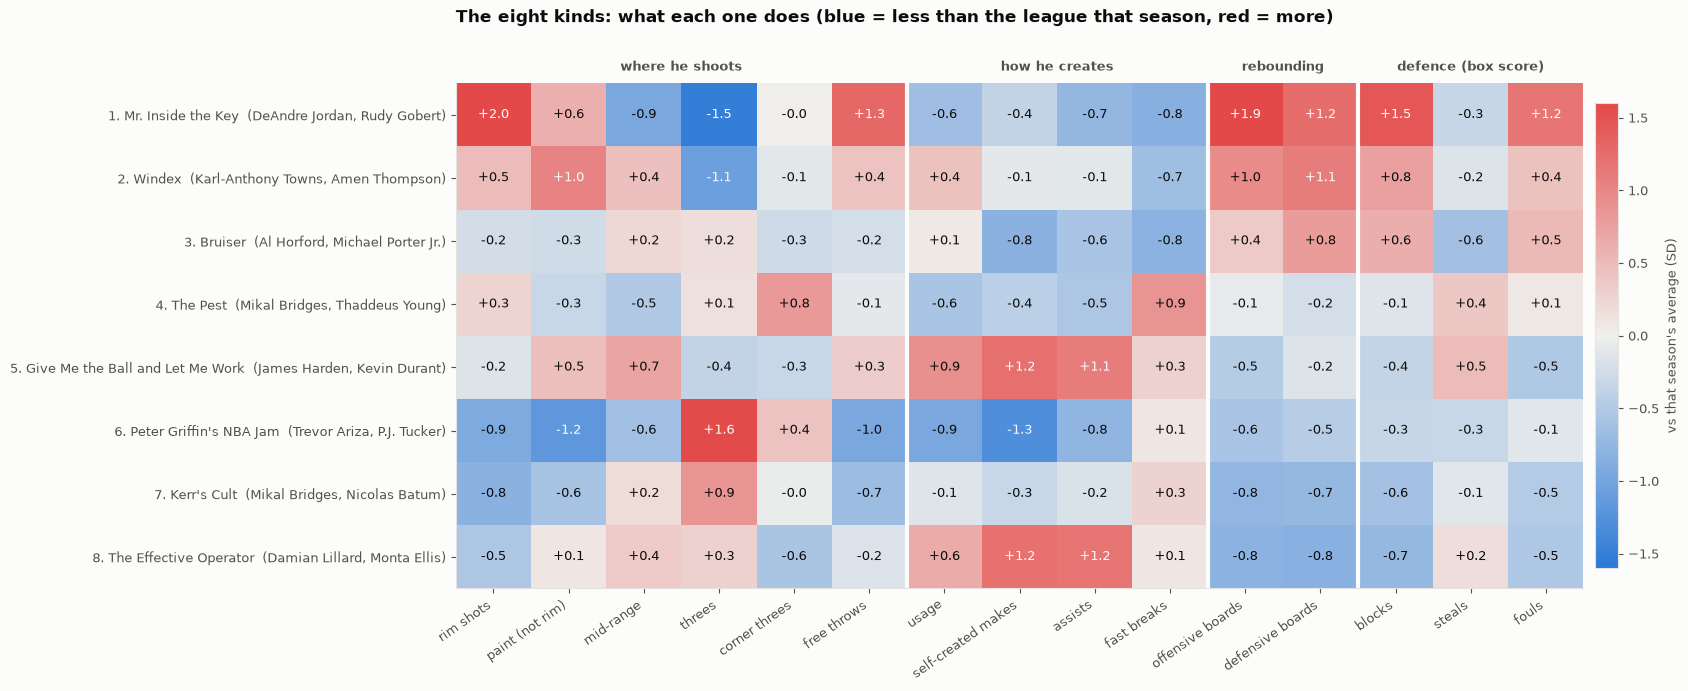

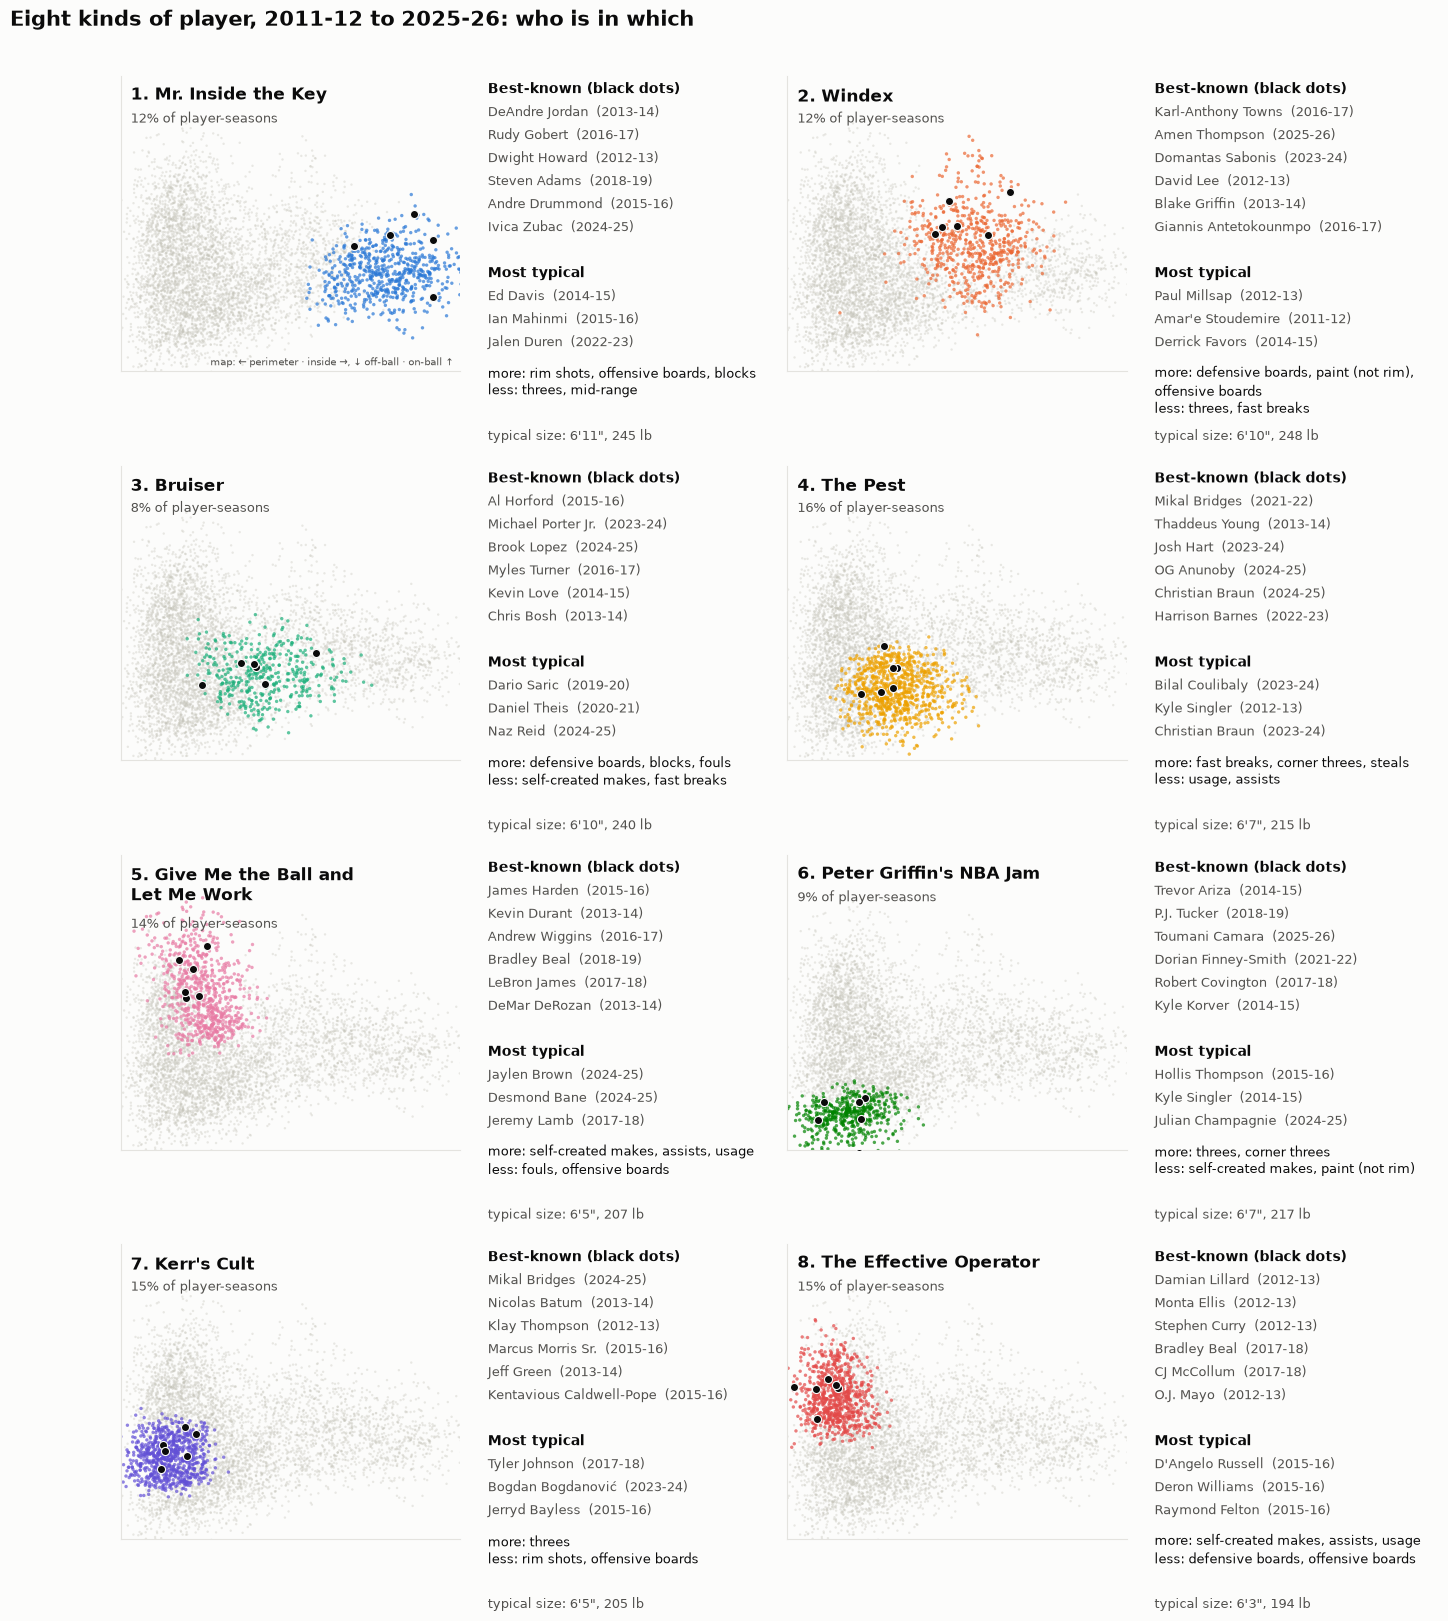

In [4]:
A.profile_heatmap(prof, known8, "2_eight_kinds_profile.png", "The eight kinds: what each one does (blue = less than the league that season, red = more)",
                  value_label="vs that season's average (SD)", names=NAMES)
A.who_is_in_which(pc, lab8, rows, known8, typical8, prof, sizes, lambda r: r["season"], "2_eight_kinds_who.png",
                  "Eight kinds of player, 2011-12 to 2025-26: who is in which", names=NAMES, unit="player-seasons");

## 2C — Players move between kinds

A player's kind is decided season by season, so a changing game shows up as a move. Some well-known cases, and where today's players sit.

In [5]:
MOVERS = ["Mikal Bridges", "Karl-Anthony Towns", "Bradley Beal", "Brook Lopez", "Draymond Green"]
moves = P[P["player_name"].isin(MOVERS)].pivot_table(index="player_name", columns="season_start", values="kind", aggfunc="first").reindex(MOVERS)
moves.columns = [f"{c % 100:02d}-{(c + 1) % 100:02d}" for c in moves.columns]
display(moves.astype("Int64").rename_axis("kind by season (1–8)"))
KNOWN = ["Nikola Jokić", "Victor Wembanyama", "Rudy Gobert", "Giannis Antetokounmpo", "Shai Gilgeous-Alexander", "Luka Dončić", "Stephen Curry",
         "Jalen Brunson", "Dyson Daniels", "Mikal Bridges", "Draymond Green", "Josh Hart", "Amen Thompson", "Cooper Flagg", "Ty Jerome"]
now = P[(P["season_start"] == 2025) & P["player_name"].isin(KNOWN)].sort_values(["kind", "player_name"])
now.groupby("kind_name", sort=False)["player_name"].apply(", ".join).rename("2025-26").to_frame().rename_axis("kind")

,12-13,13-14,14-15,15-16,16-17,17-18,18-19,19-20,20-21,21-22,22-23,23-24,24-25,25-26
kind by season (1–8),,,,,,,,,,,,,,
Mikal Bridges,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4,4,4,4,5,7,7,7
Karl-Anthony Towns,<NA>,<NA>,<NA>,2,2,2,2,2,2,2,2,3,2,2
Bradley Beal,7,7,7,8,8,8,5,8,5,5,5,5,8,<NA>
Brook Lopez,2,2,2,2,2,3,3,3,3,<NA>,3,3,3,3
Draymond Green,3,4,4,2,4,5,4,5,5,2,2,2,4,7


,2025-26
kind,
Mr. Inside the Key,Rudy Gobert
Windex,"Amen Thompson, Dyson Daniels, Giannis Antetokounmpo, Nikola Jokić, Victor Wembanyama"
The Pest,Josh Hart
Give Me the Ball and Let Me Work,"Cooper Flagg, Luka Dončić, Shai Gilgeous-Alexander"
Kerr's Cult,"Draymond Green, Mikal Bridges"
The Effective Operator,"Jalen Brunson, Stephen Curry"


## 2D — The long view: 2000-01 to 2025-26, with no era adjustment

The same eight-group exercise over 26 seasons ([D36](../docs/DECISIONS.md)), with two changes. Each player's style is pooled over a **3-season window** (steadier than one season), and the measures are put on **one scale across all 26 years**, with no comparison within the season, so that the league's changes show up directly in the mix of kinds. These groups are numbered, not named: they overlap with the eight above but not one to one.

8,932 player windows; stability at 3, 5 and 8 groups: 0.82, 0.65, 0.45


col_0,1,2,3,4,5,6,7,8
window_end,,,,,,,,
2000,0.23,0.07,0.08,0.08,0.19,0.04,0.16,0.16
2005,0.23,0.06,0.06,0.09,0.19,0.04,0.16,0.16
2010,0.23,0.04,0.07,0.07,0.18,0.10,0.16,0.15
2013,0.19,0.07,0.07,0.08,0.15,0.10,0.17,0.18
2015,0.13,0.07,0.06,0.09,0.17,0.11,0.17,0.19
2018,0.08,0.09,0.05,0.08,0.17,0.17,0.16,0.20
2020,0.06,0.09,0.06,0.08,0.19,0.18,0.16,0.19
2025,0.05,0.07,0.07,0.08,0.25,0.20,0.13,0.15


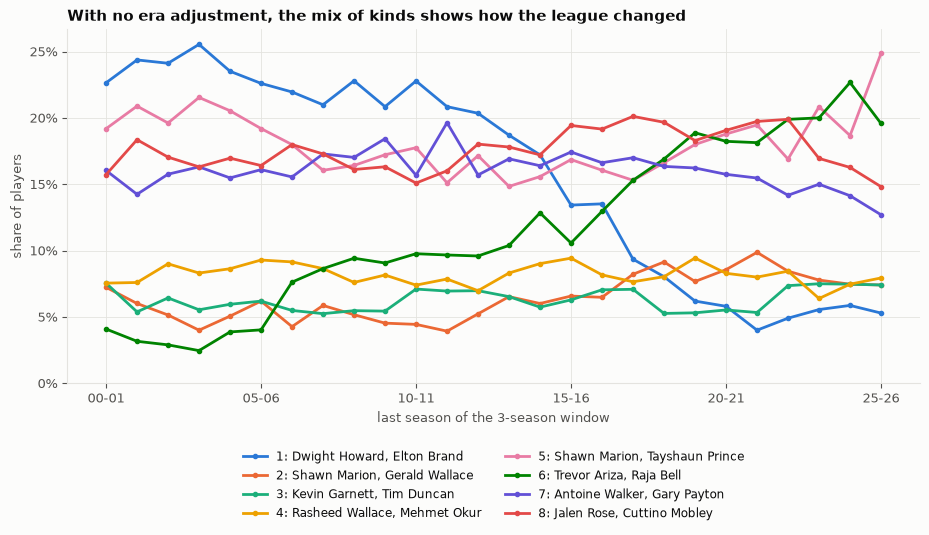

In [6]:
from unicorn.style_history import load_totals, rolling_windows

W = rolling_windows(load_totals())                                                      # 3-season windows, 500+ minutes in the last season
XW = ((W[A.FEATURES] - W[A.FEATURES].mean()) / W[A.FEATURES].std()).fillna(0).to_numpy()   # one scale over 2000-26
pcW = A.style_axes(XW)
stab = {k: A.stability(XW, k, groups=W["player_id"].to_numpy()) for k in (3, 5, 8)}      # halves split by player
labW, _, _, knownW = A.fit_clusters(XW, 8, pcW, W, minutes_col="min", min_minutes=4000)
mixW = pd.crosstab(W["window_end"], labW, normalize="index")
print(f"{len(W):,} player windows; stability at 3, 5 and 8 groups: " + ", ".join(f"{s:.2f}" for s in stab.values()))
fig, ax = plt.subplots(figsize=(11, 4.6))
for c in range(1, 9):
    ax.plot(mixW.index, mixW[c], color=SERIES8[c - 1], marker="o", markersize=3, label=f"{c}: " + ", ".join(knownW[c]["player_name"].head(2)))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylim(0, None)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025], ["00-01", "05-06", "10-11", "15-16", "20-21", "25-26"])
ax.set_xlabel("last season of the 3-season window"); ax.set_ylabel("share of players")
ax.legend(frameon=False, ncol=2, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
ax.set_title("With no era adjustment, the mix of kinds shows how the league changed", loc="left")
fig.savefig(FIG_DIR / "2_mix_2000_2026.png", dpi=150, bbox_inches="tight")
mixW.round(2).iloc[[0, 5, 10, 13, 15, 18, 20, 25]]

## Findings (13 November 2026)

**How many kinds (2A)**
- **Playing style is a continuum, not islands.** Separation is low at every count (0.25 at two groups, about 0.1 from six), so any number of groups is partly a choice of where to slice.
- **Some slices come back reliably:** three groups (stability 0.94), five (0.83) and six (0.79). Beyond six it falls: 0.59 at seven, 0.54 at eight. k-means shows the same shape.
- *Revised 13 November:* notebook 13 measured five at 0.87 and six at 0.76 from six pairs of halves, and called five a clear second peak. With 20 pairs, five and six are about equally stable. The choice of eight ([D35](../docs/DECISIONS.md)) did not rest on that gap.

**The eight kinds (2B)**

| | Kind | Share | Best-known | Does more / less |
|---|---|---|---|---|
| 1 | Mr. Inside the Key | 12% | DeAndre Jordan, Rudy Gobert, Dwight Howard | Rim shots, offensive boards, blocks / threes |
| 2 | Windex | 12% | Karl-Anthony Towns, Amen Thompson, Domantas Sabonis | Defensive boards, paint, offensive boards / threes, fast breaks |
| 3 | Bruiser | 8% | Al Horford, Michael Porter Jr., Brook Lopez | Defensive boards, blocks, fouls / self-created makes |
| 4 | The Pest | 16% | Mikal Bridges, Josh Hart, OG Anunoby | Fast breaks, corner threes, steals / usage, assists |
| 5 | Give Me the Ball and Let Me Work | 14% | James Harden, Kevin Durant, Andrew Wiggins | Self-created makes, assists, usage / fouls, offensive boards |
| 6 | Peter Griffin's NBA Jam | 9% | Trevor Ariza, P.J. Tucker, Toumani Camara | Threes, corner threes / self-created makes, paint |
| 7 | Kerr's Cult | 15% | Klay Thompson, Nicolas Batum, Mikal Bridges | Threes / rim shots, offensive boards |
| 8 | The Effective Operator | 15% | Damian Lillard, Stephen Curry, Monta Ellis | Self-created makes, assists, usage / rebounds |

- **The eight fit inside the five:** each comes mostly from one of the five coarser groups (52–100%), so eight is a finer cut of the same map, not a different one.
- **Most seasons are clear-cut:** 89% are 70% or more in one kind. In-between players exist, but they are rarer than expected.
- **Kinds 5 and 8 both create their own shots;** 8 is the smaller, pull-up guard (6'3" against 6'5") and rebounds less.

**Players move (2C)**
- **Mikal Bridges** was a Pest for four seasons, then joined Kerr's Cult. **Brook Lopez** went from Windex to Bruiser: the rim big who became a stretch big. **Draymond Green** has passed through five kinds.
- **2025-26:** Victor Wembanyama, Nikola Jokić and Giannis Antetokounmpo are Windex, because compared with the league their rebounding and paint work outweigh their threes. Draymond Green is in Kerr's Cult. Shai Gilgeous-Alexander, Luka Dončić and Cooper Flagg are Give Me the Ball; Stephen Curry and Jalen Brunson are Effective Operators.

**The long view, 2000-26 (2D)**
- **The traditional rim big fell from 23% of players to 5%.** It was the largest group until about 2012 and collapsed between 2013 (19%) and 2018 (8%).
- **The corner 3-and-D wing rose from 4% to 20%**, and the slashing wing reached 25% in the latest window, the most of any group ever.
- **These longer-run groups are less stable** (0.45 at eight, 0.82 at three): the halves are split by player, and with no era adjustment a player near a boundary switches groups as the league moves around him.